<a href="https://colab.research.google.com/github/diegoo7am/Curso-Intro-Python/blob/main/Modulo_02_Aplicaciones_Financieras/soluciones/2_4_trading_medias_moviles_sol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[⬅ Volver al índice](https://colab.research.google.com/github/diegoo7am/Curso-Intro-Python/blob/main/indice.ipynb)

# Estrategias de trading con medias móviles

En este caso vamos a aprender a trabajar con series temporales y DataFrames, calculando medias móviles y operando entre ellas para generar señales de compra y venta.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## Descarga de los datos del S&P 500

In [2]:
# auto_adjust=False: descarga también la columna 'Adj Close' (precio ajustado por dividendos y splits)
sp500 = yf.download(["SPY"], start="2018-12-31", end="2024-08-08", auto_adjust=False)
sp500 = sp500.loc[:, ["Adj Close"]]
sp500.columns = ["SP500"]

C:\dev\base_env\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\dev\base_env\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\dev\base_env\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=True)
[*********************100%*****


C:\dev\base_env\.venv\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
C:\dev\base_env\.venv\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


Calculamos los retornos

In [3]:
sp500_ret = np.log(sp500).diff().dropna()

Graficamos la serie de precios

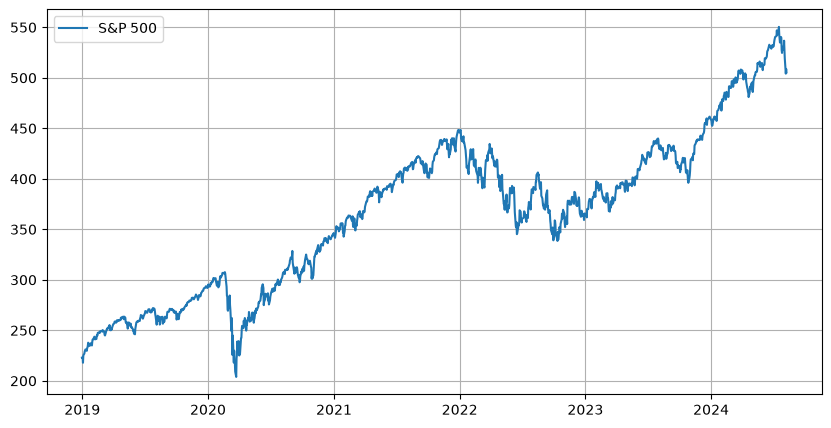

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(sp500, label="S&P 500")
plt.grid(True)
plt.legend()
plt.show()

Graficamos la serie de retornos acumulados

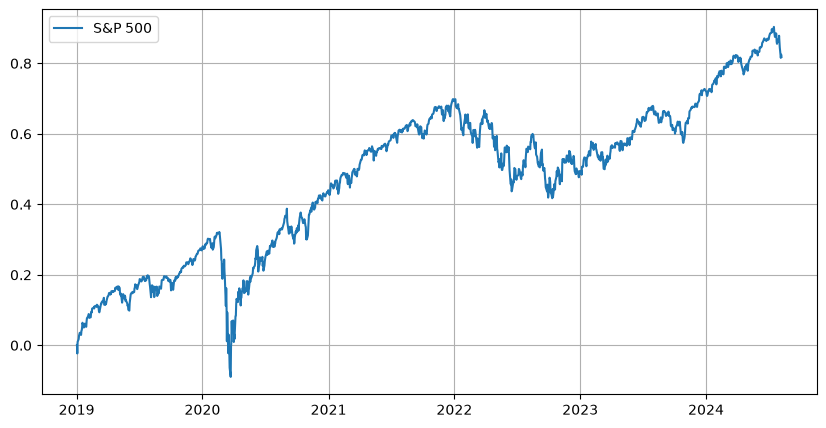

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(sp500_ret.cumsum(), label="S&P 500")
plt.grid(True)
plt.legend()
plt.show()

## ¿Qué es una ventana móvil?

Se puede definir una ventana móvil como un subconjunto de los datos originales de tamaño $w$ sobre el que se aplica una operación de reducción (media, suma, desviación típica...) que produce un único resultado. Esta ventana se mueve hacia adelante respecto al índice y se vuelve a aplicar la operación de reducción. Este proceso se repite hasta que no quedan datos que procesar.

<img src="https://raw.githubusercontent.com/diegoo7am/Curso-Intro-Python/main/Modulo_02_Aplicaciones_Financieras/imgs/ventana_movil.png" alt="Ventana móvil">

Veamos un ejemplo con la **media** calculada con una **ventana móvil** de **tamaño 5**.

Ref.:
* Función **rolling**: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html

**Fórmula de la media móvil simple** con una ventana de $w$ días:

$$SMA_t = \frac{P_t + P_{t-1} + \dots + P_{t-w+1}}{w}$$

In [6]:
df = pd.DataFrame(
    {
        "SP500": sp500["SP500"],
        "SMA": sp500["SP500"].rolling(window=5).mean()
    }
)
df.head(10)

,SP500,SMA
Date,,
2018-12-31,223.019547,NaN
2019-01-02,223.251617,NaN
2019-01-03,217.924149,NaN
2019-01-04,225.223694,NaN
2019-01-07,226.999496,223.283701
2019-01-08,229.132278,224.506247
2019-01-09,230.203125,225.896548
2019-01-10,231.015137,228.514746
2019-01-11,231.104385,229.690884


## ¿Cuáles son los tipos principales de medias móviles?

* **Media Móvil Simple** (Simple Moving Average - SMA): todos los datos de la ventana tienen el mismo peso o importancia.
* **Media Móvil Exponencial** (Exponential Moving Average - EMA): los datos más recientes tienen más peso o importancia que los más lejanos en el tiempo.

Ref.:
* Función **ewm**: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html

**Fórmula de la media móvil exponencial:**

$$EMA_t = \alpha \times P_t + (1 - \alpha) \times EMA_{t-1}, \qquad \alpha = \frac{2}{span + 1}$$

Cuanto menor es el `span`, mayor es $\alpha$ y más peso tienen los precios recientes.

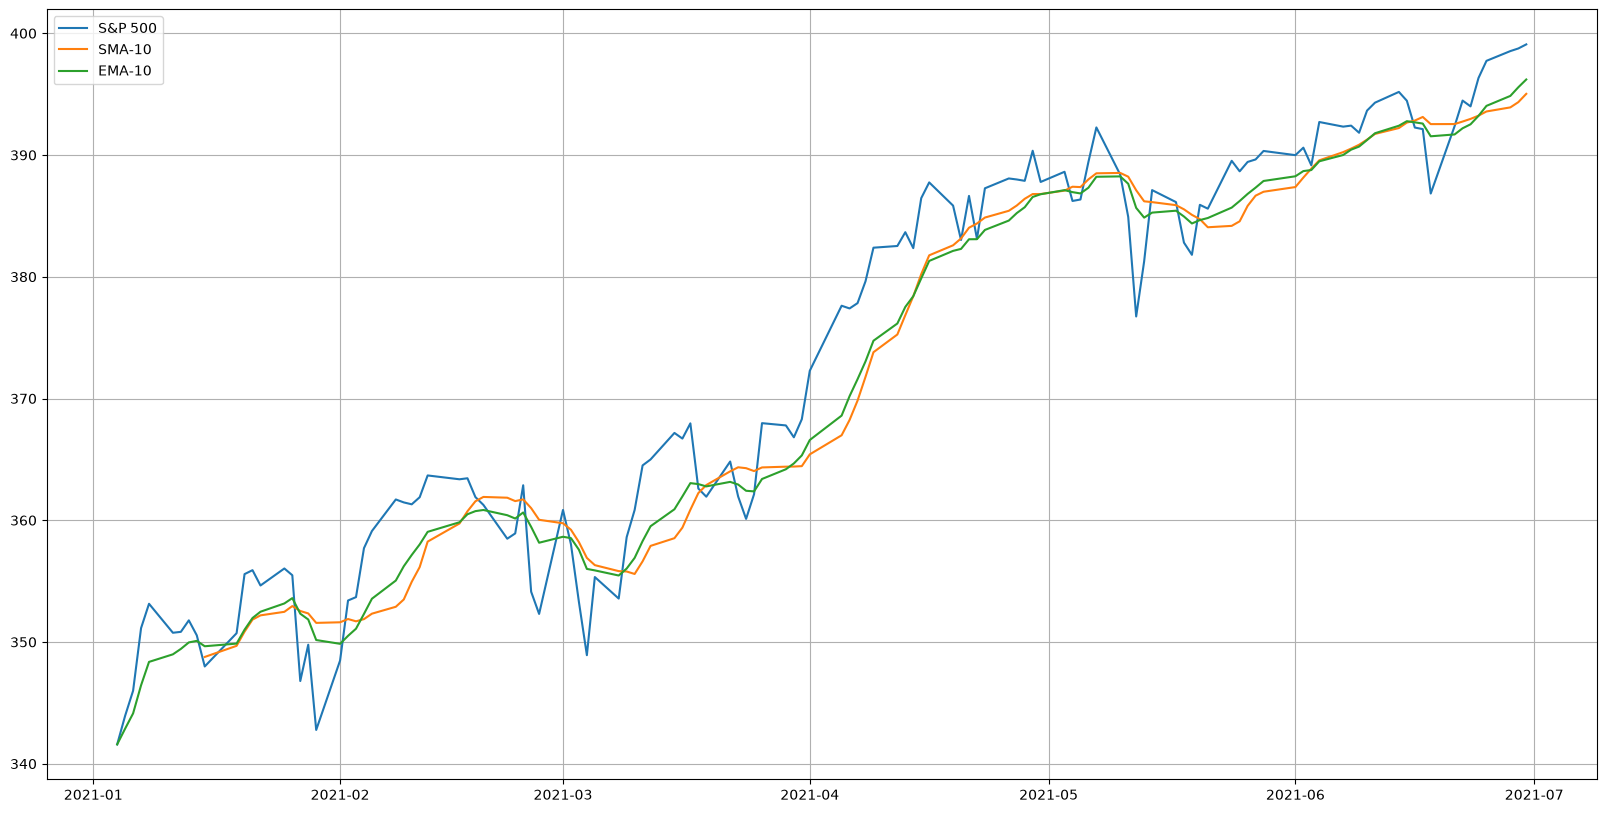

In [7]:
serie = sp500.loc["2021-01":"2021-06", :]

plt.figure(figsize=(20, 10))
plt.plot(serie, label="S&P 500")
plt.plot(serie.rolling(window=10).mean(), label="SMA-10")
plt.plot(serie.ewm(span=10).mean(), label="EMA-10")
plt.grid(True)
plt.legend()
plt.show()

## ¿Para qué se utilizan las medias móviles en trading?

Fundamentalmente para:
1. **Detectar tendencias** en los activos.
2. **Suavizar el ruido** de los precios.

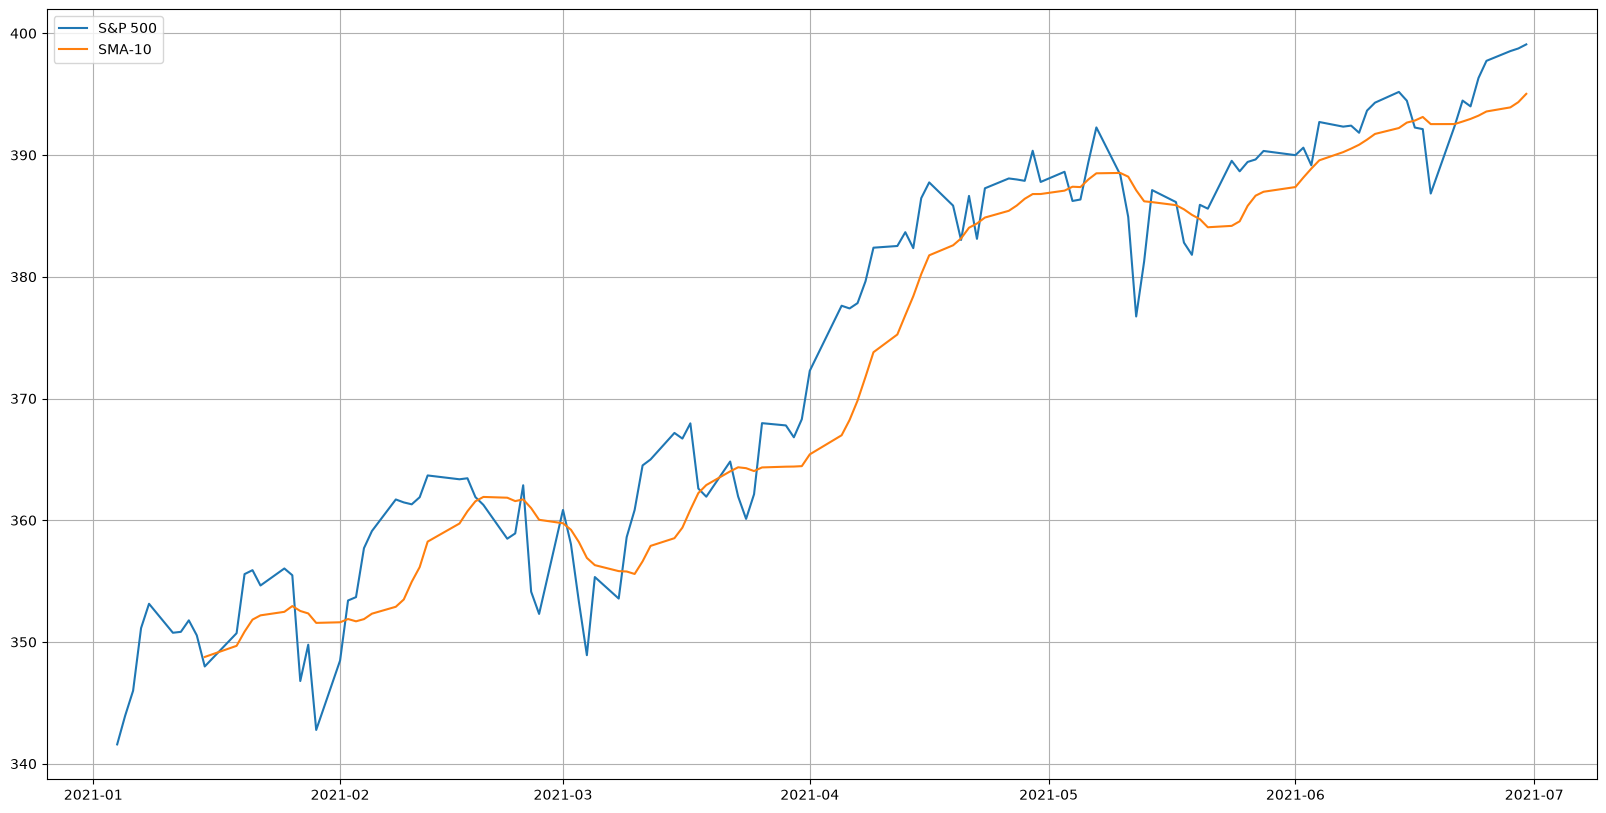

In [8]:
serie = sp500.loc["2021-01":"2021-06", :]

plt.figure(figsize=(20, 10))
plt.plot(serie, label="S&P 500")
plt.plot(serie.rolling(10).mean(), label="SMA-10")
plt.grid(True)
plt.legend()
plt.show()

## Bandas Bollinger

* SMA de 20 días.
* +/- 2 desviaciones típicas rolling.

$$\text{Banda superior} = SMA_{20} + 2 \times \sigma_{20} \qquad \text{Banda inferior} = SMA_{20} - 2 \times \sigma_{20}$$

donde $\sigma_{20}$ es la desviación típica de los precios de los últimos 20 días.

Ref.:
* Bandas Bollinger: https://www.tecnicasdetrading.com/2024/01/bandas-de-bollinger-python-con-pandas-numpy.html

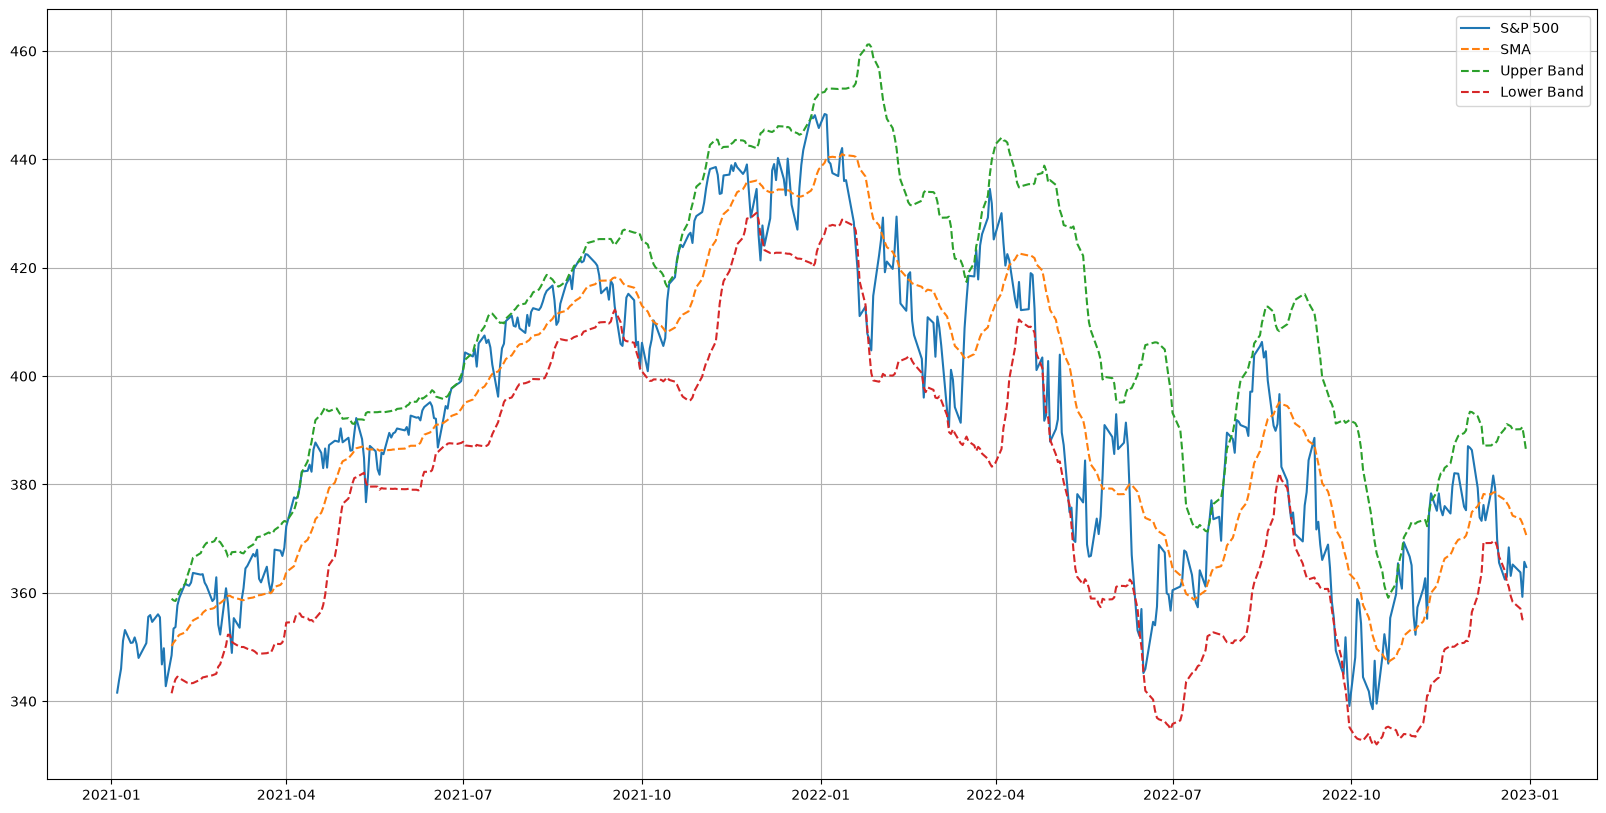

In [9]:
w = 20
data = sp500.loc["2021":"2022", :].copy()
data["SMA"] = data["SP500"].rolling(window=w).mean()
data["std"] = data["SP500"].rolling(window=w).std()
data["UpperBand"] = data["SMA"] + 2 * data["std"]
data["LowerBand"] = data["SMA"] - 2 * data["std"]

plt.figure(figsize=(20, 10))
plt.plot(data["SP500"], label="S&P 500")
plt.plot(data["SMA"], label="SMA", linestyle="--")
plt.plot(data["UpperBand"], label="Upper Band", linestyle="--")
plt.plot(data["LowerBand"], label="Lower Band", linestyle="--")
plt.grid(True)
plt.legend()
plt.show()

## Estrategia *crossover* con una *SMA-Short* y una *SMA-Long*

Consiste en combinar una media móvil con una ventana pequeña que reacciona antes a los cambios (SMA-Short), y una media móvil con una ventana grande que detecta tendencias a largo plazo (SMA-Long). Utilizaremos los cortes de la SMA-Short con la SMA-Long para generar de señales de compra y venta:

* Cuando SMA-Short corta SMA-Long hacia arriba: compramos.
* Cuando SMA-Short corta SMA-Long hacia abajo: vendemos.

En el código, la señal se obtiene así: se marca con 1 los días en que $SMA_{short} > SMA_{long}$ y con 0 el resto. La **diferencia** entre un día y el anterior vale $+1$ el día del cruce hacia arriba (compra) y $-1$ el día del cruce hacia abajo (venta).

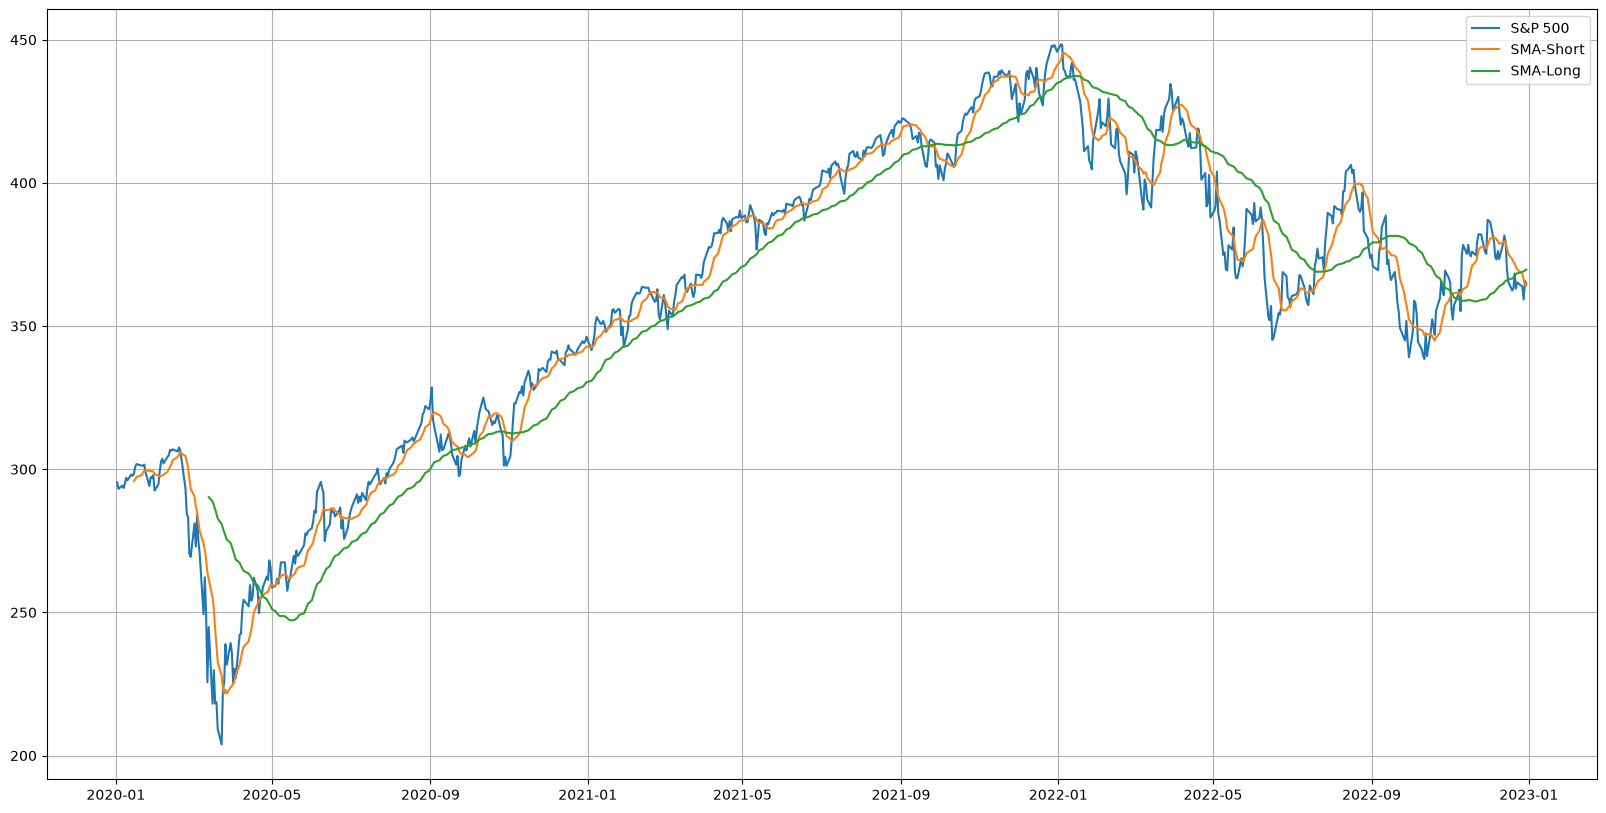

In [10]:
serie = sp500.loc["2020":"2022", :]

plt.figure(figsize=(20, 10))
plt.plot(serie, label="S&P 500")
plt.plot(serie.rolling(10).mean(), label="SMA-Short")
plt.plot(serie.rolling(50).mean(), label="SMA-Long")
plt.grid(True)
plt.legend()
plt.show()

In [11]:
def generar_senales_compra_venta(short:pd.Series, long:pd.Series) -> pd.DataFrame:
    """Genera las señales de compra (+1.0) y venta (-1.0) en función de dos
    medias móviles con dos tamaños de ventana distintos.

    Args:
        short (pd.Series): SMA-Short
        long (pd.Series): SMA-Long

    Returns:
        pd.DataFrame: ["short", "long", "signal"]
    """
    # Concatenamos las dos series por columnas en un solo dataframe.
    data = pd.concat([short, long], axis=1)
    # Renombramos las columnas.
    data.columns = ["short", "long"]
    # Calculamos la diferencia entre las dos medias móviles.
    data["diff"] = data["short"] - data["long"]
    # Generamos las señales de compra y venta.
    data.loc[data["diff"] <= 0, ["diff"]] = 0
    data.loc[data["diff"] > 0, ["diff"]] = 1
    data["diff_shift1"] = data["diff"].shift(1)
    data["signal"] = data["diff"] - data["diff_shift1"]
    # Eliminamos las columnas auxiliares y devolvemos el dataframe.
    return data.loc[:, ["short", "long", "signal"]]

def graficar_senales_compra_venta(data:pd.DataFrame, base_label:str, short_label:str, long_label:str, buy_label:str, sell_label:str):
    """Genera un gráfico con las series de datos y las señales de compra y venta.

    Args:
        data (pd.DataFrame): DataFrame con las columnas ["base", "short", "long", "signal"]
        base_label (str): Etiqueta para la serie base de precios.
        short_label (str): Etiqueta para la serie que representa la media móvil de período corto.
        long_label (str): Etiqueta para la series que representa la media móvil de período largo.
        buy_label (str): Etiqueta para la serie de señales de compra.
        sell_label (str): Etiqueta para la setie de señales de venta.
    """
    plt.figure(figsize=(20, 10))
    plt.plot(data["base"], label=base_label, zorder=1)
    plt.plot(data["short"], label=short_label, zorder=2)
    plt.plot(data["long"], label=long_label, zorder=3)
    plt.scatter(
        data.loc[data["signal"] == 1].index,
        data.loc[data["signal"] == 1, ["long"]],
        marker="^",
        edgecolor="black",
        linewidth=1,
        color="green",
        label=buy_label,
        zorder=4,
    )
    plt.scatter(
        data.loc[data["signal"] == -1].index,
        data.loc[data["signal"] == -1, ["long"]],
        marker="v",
        edgecolor="black",
        linewidth=1,
        color="red",
        label=sell_label,
        zorder=5,
    )
    plt.grid(True)
    plt.legend()
    plt.show()

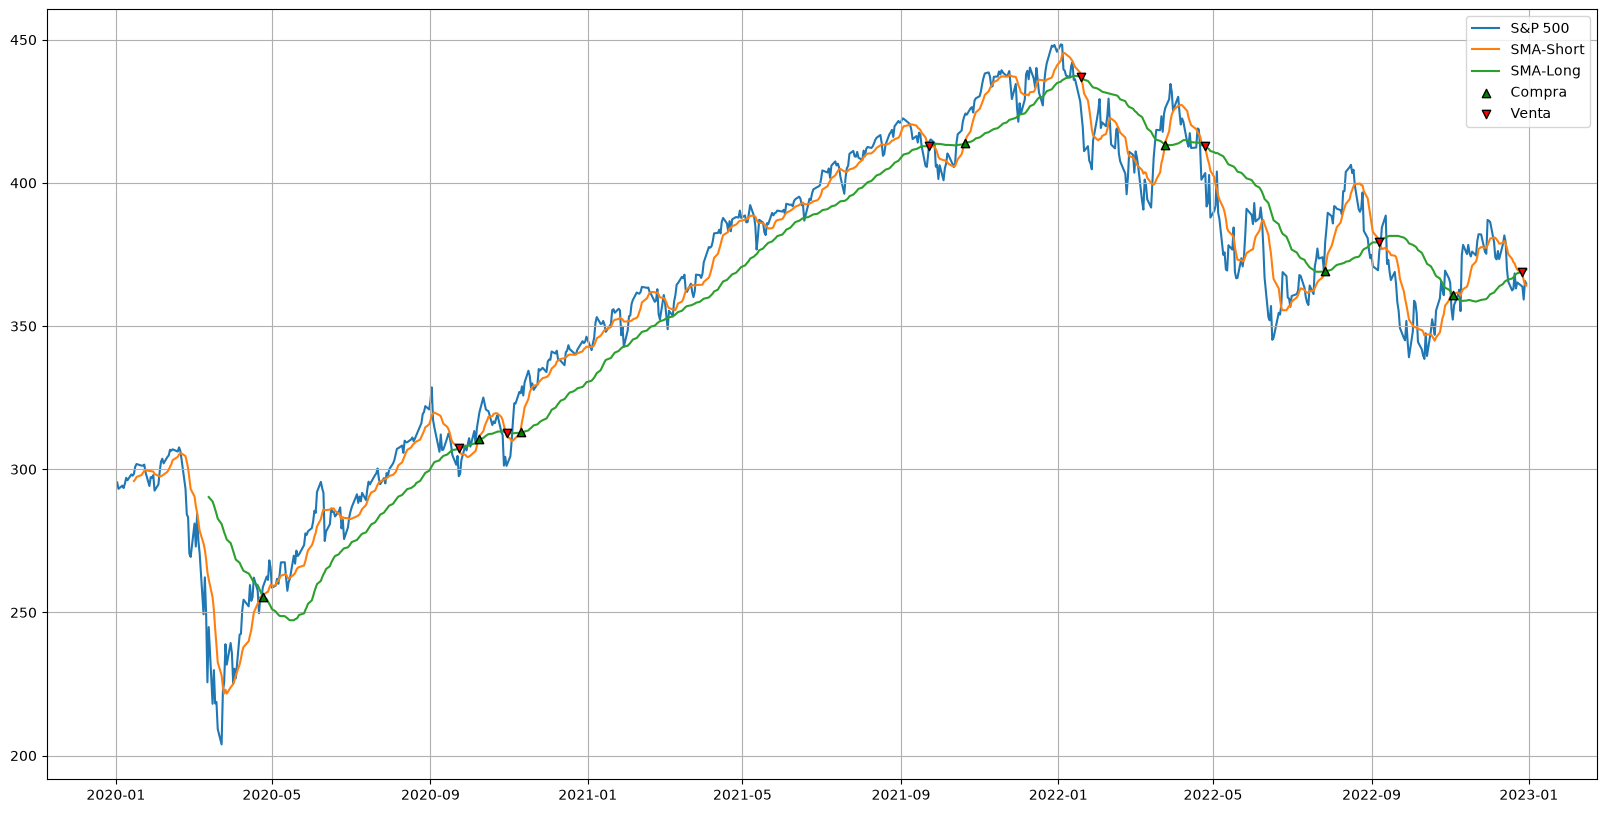

In [12]:
serie = sp500.loc["2020":"2022", :]
short = serie.rolling(10).mean()
long = serie.rolling(50).mean()

data = generar_senales_compra_venta(short, long)

data["base"] = serie["SP500"]

graficar_senales_compra_venta(data, "S&P 500", "SMA-Short", "SMA-Long", "Compra", "Venta")

## Estrategia *crossover* con una *EWM-Short* y una *SMA-Long*

Consiste en combinar una media móvil exponencial con una ventana pequeña que reacciona antes a los cambios (EWM-Short), y una media móvil con una ventana grande que detecta tendencias a largo plazo (SMA-Long). Utilizaremos los cortes de la EWM-Short con la SMA-Long para generar de señales de compra y venta:

* Cuando EWM-Short corta SMA-Long hacia arriba: compramos.
* Cuando EWM-Short corta SMA-Long hacia abajo: vendemos.

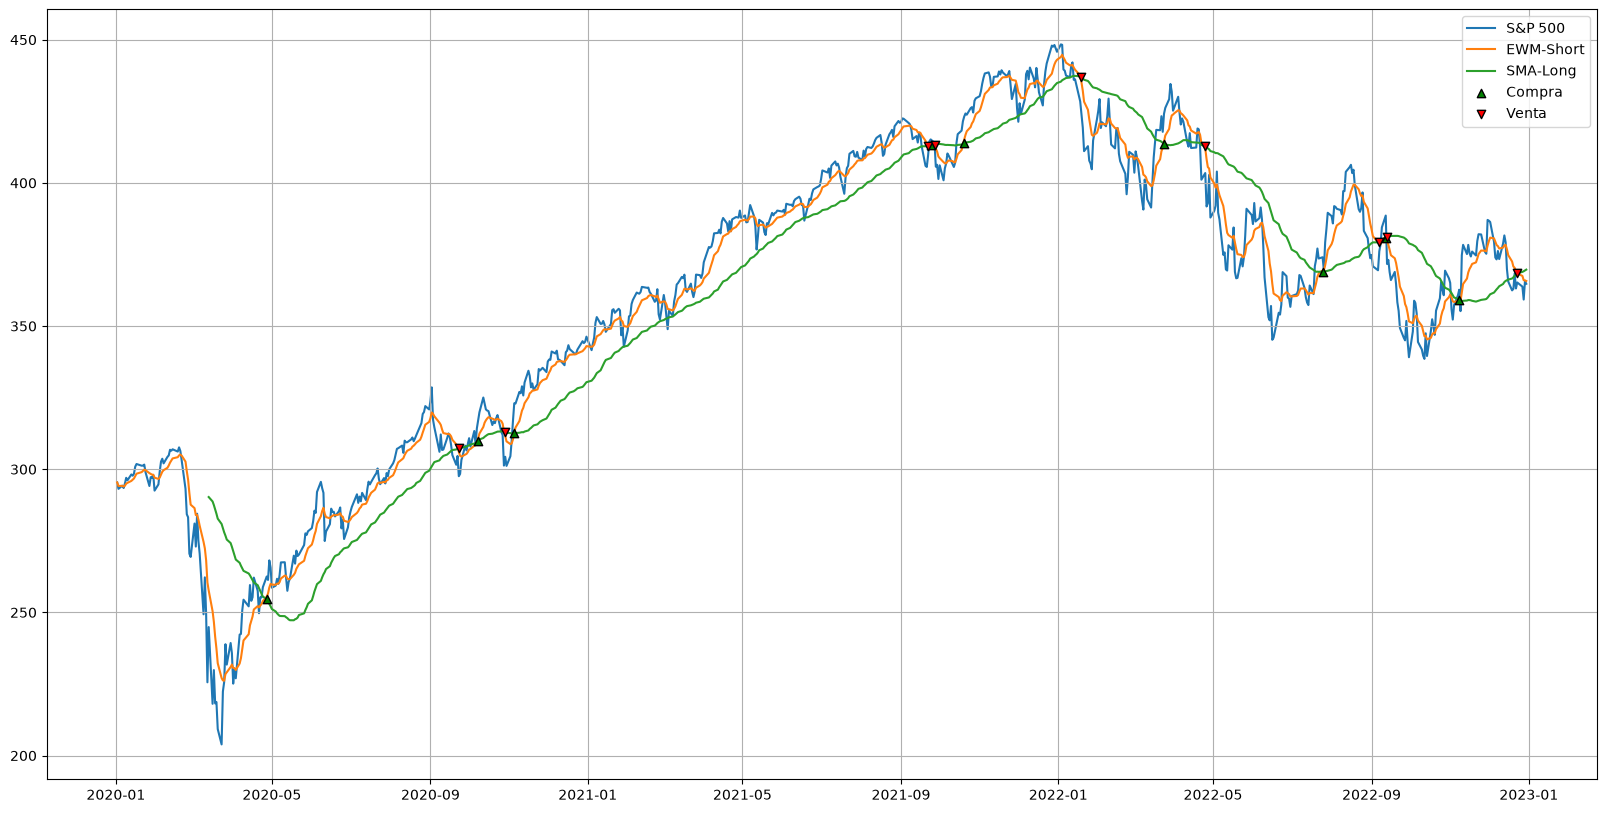

In [13]:
serie = sp500.loc["2020":"2022", :]
short = serie.ewm(span=10).mean()
long = serie.rolling(window=50).mean()

data = generar_senales_compra_venta(short, long)

data["base"] = serie["SP500"]

graficar_senales_compra_venta(
    data=data,
    base_label="S&P 500",
    short_label="EWM-Short",
    long_label="SMA-Long",
    buy_label="Compra",
    sell_label="Venta"
)

<div style="background-color: #e0f7fa; padding: 10px;">

**EJERCICIO** ¿Habría merecido la pena seguir la estrategia *crossover* SMA-10 / SMA-50 entre 2020 y 2022?

- Considera que estamos invertidos en el S&P 500 cuando la SMA-Short está por encima de la SMA-Long y fuera del mercado en caso contrario. Como la señal se conoce al cierre, operamos al día siguiente.
- Calcula la rentabilidad acumulada (logarítmica) de la estrategia y compárala con la de comprar y mantener (*buy & hold*) en un gráfico.
- ¿Cuántos días hemos estado invertidos?

</div>

**Fórmulas:**

$$r^{estrategia}_t = \text{posición}_{t-1} \times r_t, \qquad \text{posición} = \begin{cases} 1 & \text{si } SMA_{short} > SMA_{long} \\ 0 & \text{en otro caso} \end{cases}$$

donde $r_t = \ln(P_t / P_{t-1})$. La rentabilidad total de un periodo, a partir de las rentabilidades logarítmicas, es:

$$R_{total} = e^{\sum_t r_t} - 1$$

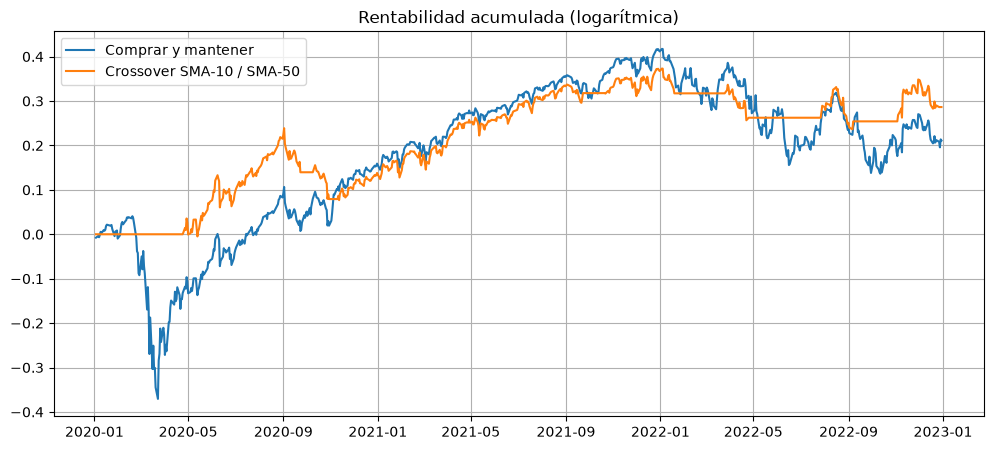

Rentabilidad total comprar y mantener: 23.49%
Rentabilidad total estrategia:          33.16%
Días invertidos: 484 de 755


In [14]:
serie = sp500.loc["2020":"2022", "SP500"]
short = serie.rolling(10).mean()   # SMA de 10 sesiones
long = serie.rolling(50).mean()    # SMA de 50 sesiones

# 1 = invertidos, 0 = fuera del mercado. (short > long) da True/False y astype(int) lo pasa a 1/0
# shift(1): desplaza la señal un día, porque operamos al día siguiente de conocerla
posicion = (short > long).astype(int).shift(1)

rent = np.log(serie).diff()                       # rentabilidad logarítmica diaria
rent_estrategia = (posicion * rent).dropna()      # solo ganamos/perdemos los días que estamos invertidos
rent_buy_hold = rent.loc[rent_estrategia.index]   # mismas fechas para comparar

# La suma acumulada de rentabilidades logarítmicas es la rentabilidad acumulada
plt.figure(figsize=(12, 5))
plt.plot(rent_buy_hold.cumsum(), label="Comprar y mantener")
plt.plot(rent_estrategia.cumsum(), label="Crossover SMA-10 / SMA-50")
plt.title("Rentabilidad acumulada (logarítmica)")
plt.grid(True)
plt.legend()
plt.show()

# np.exp(suma) - 1 convierte la rentabilidad logarítmica total en rentabilidad en %
print(f"Rentabilidad total comprar y mantener: {np.exp(rent_buy_hold.sum()) - 1:.2%}")
print(f"Rentabilidad total estrategia:          {np.exp(rent_estrategia.sum()) - 1:.2%}")
print(f"Días invertidos: {int(posicion.loc[rent_estrategia.index].sum())} de {len(rent_estrategia)}")

## ¿Cómo medimos si una estrategia es buena?

Fijarse solo en la rentabilidad total es engañoso: dos estrategias pueden acabar ganando lo mismo y una de ellas haber pasado por caídas enormes por el camino. Para comparar estrategias se usan **métricas que tienen en cuenta el riesgo**.

**Rentabilidad y volatilidad anualizadas** (ya las vimos en el 2_3):

$$\mu_{anual} = \bar{r} \times 252 \qquad \sigma_{anual} = \sigma_r \times \sqrt{252}$$

**Ratio de Sharpe**: cuánta rentabilidad obtenemos por cada unidad de riesgo (volatilidad). Cuanto más alto, mejor. Para simplificar, suponemos que el tipo libre de riesgo es 0:

$$Sharpe = \frac{\mu_{anual}}{\sigma_{anual}}$$

**Drawdown**: cuánto ha caído la inversión desde su último máximo. Si $V_t = e^{\sum_{s \le t} r_s}$ es el valor de 1 € invertido al principio:

$$Drawdown_t = \frac{V_t}{\max_{s \le t} V_s} - 1$$

El **máximo drawdown** es la peor caída de todo el periodo (el valor más negativo del drawdown). Es la métrica que mide "el peor momento" que habría vivido un inversor.

Primero recalculamos las rentabilidades diarias de la estrategia SMA-10 / SMA-50 del ejercicio anterior y las de comprar y mantener:

In [15]:
serie = sp500.loc["2020":"2022", "SP500"]
posicion = (serie.rolling(10).mean() > serie.rolling(50).mean()).astype(int).shift(1)

rent = np.log(serie).diff()
rent_estrategia = (posicion * rent).dropna()
rent_buy_hold = rent.loc[rent_estrategia.index]

Para calcular el máximo alcanzado **hasta cada día** usamos `cummax()` (máximo acumulado). Veamos un ejemplo sencillo:

Ref.:
* Función **cummax**: https://pandas.pydata.org/docs/reference/api/pandas.Series.cummax.html

In [16]:
valores = pd.Series([100, 120, 90, 130, 110])

pd.DataFrame({
    "valor": valores,
    "maximo_hasta_hoy": valores.cummax(),
    "drawdown": valores / valores.cummax() - 1,
})

,valor,maximo_hasta_hoy,drawdown
0,100,100,0.000000
1,120,120,0.000000
2,90,120,-0.250000
3,130,130,0.000000
4,110,130,-0.153846


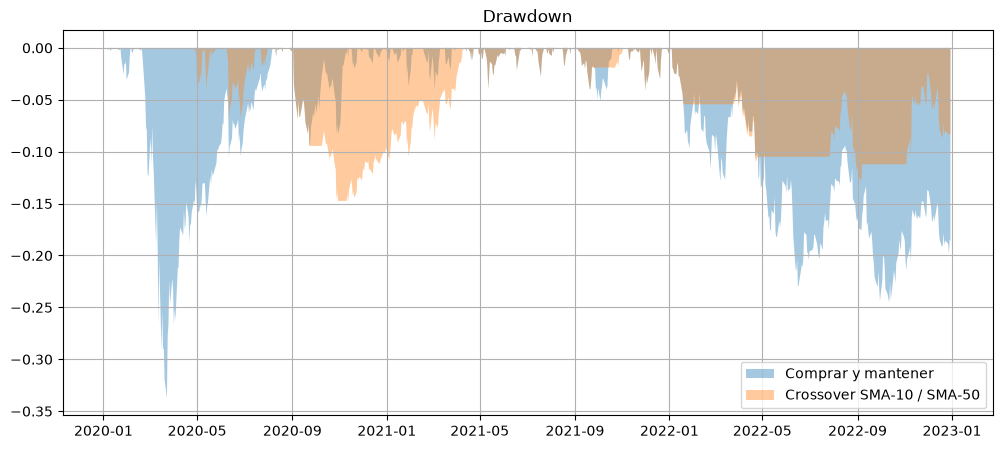

In [17]:
def calcular_drawdown(rent: pd.Series) -> pd.Series:
    """Calcula el drawdown diario a partir de rentabilidades logarítmicas.

    Args:
        rent (pd.Series): Rentabilidades logarítmicas diarias.

    Returns:
        pd.Series: Drawdown de cada día (0 en máximos, negativo en caídas).
    """
    valor = np.exp(rent.cumsum())   # valor de 1 € invertido al principio
    maximo = valor.cummax()         # máximo alcanzado hasta cada día
    return valor / maximo - 1


dd_buy_hold = calcular_drawdown(rent_buy_hold)
dd_estrategia = calcular_drawdown(rent_estrategia)

plt.figure(figsize=(12, 5))
plt.fill_between(dd_buy_hold.index, dd_buy_hold, 0, alpha=0.4, label="Comprar y mantener")
plt.fill_between(dd_estrategia.index, dd_estrategia, 0, alpha=0.4, label="Crossover SMA-10 / SMA-50")
plt.title("Drawdown")
plt.grid(True)
plt.legend()
plt.show()

Agrupamos todas las métricas en una función que devuelve una `pd.Series`. Así podemos construir una tabla comparativa con un `DataFrame` en el que cada columna es una estrategia.

In [18]:
def calcular_metricas(rent: pd.Series) -> pd.Series:
    """Calcula las métricas principales de una estrategia.

    Args:
        rent (pd.Series): Rentabilidades logarítmicas diarias de la estrategia.

    Returns:
        pd.Series: Rentabilidad total, rentabilidad y volatilidad anualizadas,
            ratio de Sharpe y máximo drawdown.
    """
    rent_anual = rent.mean() * 252
    vol_anual = rent.std() * np.sqrt(252)
    return pd.Series({
        "Rentabilidad total": np.exp(rent.sum()) - 1,
        "Rentabilidad anual": rent_anual,
        "Volatilidad anual": vol_anual,
        "Sharpe": rent_anual / vol_anual,
        "Máx. drawdown": calcular_drawdown(rent).min(),
    })


tabla = pd.DataFrame({
    "Comprar y mantener": calcular_metricas(rent_buy_hold),
    "SMA-10 / SMA-50": calcular_metricas(rent_estrategia),
})
tabla.round(3)

,Comprar y mantener,SMA-10 / SMA-50
Rentabilidad total,0.235,0.332
Rentabilidad anual,0.070,0.096
Volatilidad anual,0.251,0.134
Sharpe,0.280,0.713
Máx. drawdown,-0.337,-0.149


<div style="background-color: #e0f7fa; padding: 10px;">

**EJERCICIO** Compara la estrategia *crossover* **EWM-10 / SMA-50** con las dos anteriores entre 2020 y 2022.

- Calcula sus rentabilidades diarias igual que hicimos con la SMA-10 / SMA-50 (usa las mismas fechas que `rent_estrategia`).
- Añádela como una tercera columna a la `tabla` usando `calcular_metricas`.
- ¿Qué estrategia tiene mejor Sharpe? ¿Y menor drawdown? Pista: `tabla.loc["Sharpe"].idxmax()`.

</div>

In [19]:
serie = sp500.loc["2020":"2022", "SP500"]
short = serie.ewm(span=10).mean()     # EWM de 10 sesiones
long = serie.rolling(50).mean()       # SMA de 50 sesiones

# Misma lógica que antes: invertidos cuando short > long, operando al día siguiente
posicion_ewm = (short > long).astype(int).shift(1)
rent = np.log(serie).diff()
rent_ewm = (posicion_ewm * rent).loc[rent_estrategia.index]   # mismas fechas que las otras

# Añadir una columna nueva a un DataFrame es tan fácil como asignarla
tabla["EWM-10 / SMA-50"] = calcular_metricas(rent_ewm)
display(tabla.round(3))

# idxmax devuelve el nombre de la columna con el valor máximo de esa fila.
# El drawdown es negativo, así que el "menor" drawdown es el valor más alto (más cercano a 0).
print(f"Mejor Sharpe:    {tabla.loc['Sharpe'].idxmax()}")
print(f"Menor drawdown:  {tabla.loc['Máx. drawdown'].idxmax()}")

,Comprar y mantener,SMA-10 / SMA-50,EWM-10 / SMA-50
Rentabilidad total,0.235,0.332,0.270
Rentabilidad anual,0.070,0.096,0.080
Volatilidad anual,0.251,0.134,0.137
Sharpe,0.280,0.713,0.582
Máx. drawdown,-0.337,-0.149,-0.153


Mejor Sharpe:    SMA-10 / SMA-50
Menor drawdown:  SMA-10 / SMA-50


## Optimización de parámetros: ¿por qué 10 y 50?

Hasta ahora hemos elegido las ventanas de las medias móviles "a ojo". Una pregunta natural es: **¿qué combinación de ventanas habría funcionado mejor?** Para responderla, metemos el *backtest* en una función y la ejecutamos con muchas combinaciones de parámetros.

Un detalle importante: una SMA de 200 sesiones necesita 200 días de historia antes de dar su primer valor. Por eso calculamos las medias sobre **toda** la serie de precios y solo después recortamos el periodo que queremos evaluar (`inicio`, `fin`). Por este motivo los resultados de SMA-10 / SMA-50 son ligeramente distintos a los de antes (allí los primeros 50 días del periodo estábamos fuera del mercado).

In [20]:
def backtest_crossover(precios: pd.Series, w_short: int, w_long: int, inicio: str, fin: str) -> pd.Series:
    """Calcula las rentabilidades diarias de una estrategia crossover SMA-Short / SMA-Long.

    Args:
        precios (pd.Series): Serie de precios completa.
        w_short (int): Ventana de la media móvil corta.
        w_long (int): Ventana de la media móvil larga.
        inicio (str): Fecha de inicio del periodo a evaluar.
        fin (str): Fecha de fin del periodo a evaluar.

    Returns:
        pd.Series: Rentabilidades logarítmicas diarias de la estrategia en [inicio, fin].
    """
    short = precios.rolling(w_short).mean()
    long = precios.rolling(w_long).mean()
    posicion = (short > long).astype(int).shift(1)
    rent = np.log(precios).diff()
    return (posicion * rent).loc[inicio:fin]


precios = sp500["SP500"]
calcular_metricas(backtest_crossover(precios, 10, 50, "2020", "2022")).round(3)

Rentabilidad total    0.226
Rentabilidad anual    0.068
Volatilidad anual     0.141
Sharpe                0.480
Máx. drawdown        -0.149
dtype: float64

Probamos todas las combinaciones de ventanas con un **doble bucle `for`**. Guardamos los resultados de cada combinación en un diccionario, los acumulamos en una lista y al final la convertimos en un `DataFrame`.

In [21]:
ventanas_short = [5, 10, 20, 30]
ventanas_long = [50, 100, 150, 200]

resultados = []
for w_short in ventanas_short:
    for w_long in ventanas_long:
        rent_e = backtest_crossover(precios, w_short, w_long, "2020", "2022")
        metricas = calcular_metricas(rent_e)
        resultados.append({
            "short": w_short,
            "long": w_long,
            "Rentabilidad total": metricas["Rentabilidad total"],
            "Sharpe": metricas["Sharpe"],
            "Máx. drawdown": metricas["Máx. drawdown"],
        })

resultados = pd.DataFrame(resultados)
resultados.sort_values("Sharpe", ascending=False).round(3).head()

,short,long,Rentabilidad total,Sharpe,Máx. drawdown
2,5,150,0.282,0.617,-0.173
5,10,100,0.249,0.535,-0.194
4,10,50,0.226,0.480,-0.149
0,5,50,0.215,0.479,-0.171
1,5,100,0.151,0.347,-0.220


Para verlo de un vistazo, reorganizamos los resultados con `pivot` (ventana corta en filas, ventana larga en columnas) y dibujamos un **mapa de calor** con `plt.imshow`.

Ref.:
* Función **pivot**: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html
* Función **imshow**: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html

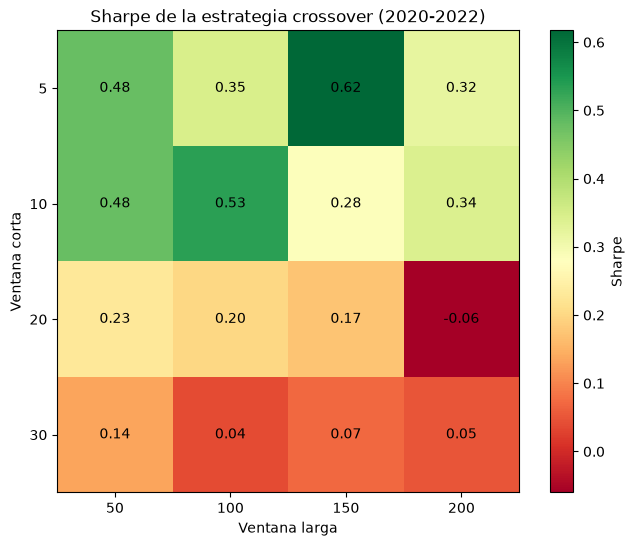

In [22]:
tabla_sharpe = resultados.pivot(index="short", columns="long", values="Sharpe")

plt.figure(figsize=(8, 6))
plt.imshow(tabla_sharpe.values, cmap="RdYlGn")
plt.colorbar(label="Sharpe")
plt.xticks(range(len(tabla_sharpe.columns)), tabla_sharpe.columns)
plt.yticks(range(len(tabla_sharpe.index)), tabla_sharpe.index)
plt.xlabel("Ventana larga")
plt.ylabel("Ventana corta")

# Escribimos el valor del Sharpe en el centro de cada casilla
for i in range(len(tabla_sharpe.index)):
    for j in range(len(tabla_sharpe.columns)):
        plt.text(j, i, f"{tabla_sharpe.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Sharpe de la estrategia crossover (2020-2022)")
plt.show()

## Cuidado con el sobreajuste (*overfitting*)

Elegir los parámetros que mejor funcionaron en el pasado es muy tentador, pero tiene trampa: **con suficientes combinaciones, alguna saldrá bien por pura casualidad**. Esa combinación se ha "ajustado" al ruido de ese periodo concreto, y no hay garantía de que funcione en el futuro.

Para comprobarlo se separan los datos en dos partes:

* **Dentro de muestra (*in-sample*)**: el periodo que usamos para elegir los parámetros (aquí, 2020-2022).
* **Fuera de muestra (*out-of-sample*)**: un periodo posterior que **no** hemos mirado al elegir, y que hace de "futuro" (aquí, 2023 - agosto 2024).

Si la estrategia solo funciona dentro de muestra, probablemente estamos ante un caso de sobreajuste.

<div style="background-color: #e0f7fa; padding: 10px;">

**EJERCICIO** ¿Se mantiene la mejor combinación fuera de muestra?

- Obtén la combinación de ventanas con mayor Sharpe en 2020-2022 a partir de `resultados`. Pista: `resultados["Sharpe"].idxmax()` devuelve la fila del máximo.
- Evalúa esa combinación entre 2023 y 2024 con `backtest_crossover`, y compárala con la SMA-10 / SMA-50 y con comprar y mantener en ese mismo periodo: tabla con `calcular_metricas` y gráfico de rentabilidad acumulada.
- **Extra**: repite el doble bucle para 2023-2024. ¿En qué puesto queda la combinación ganadora de 2020-2022?

</div>

Mejor combinación 2020-2022: SMA-5 / SMA-150 (Sharpe 0.62)


,Comprar y mantener,SMA-10 / SMA-50,SMA-5 / SMA-150
Rentabilidad total,0.386,0.217,0.278
Rentabilidad anual,0.205,0.123,0.154
Volatilidad anual,0.128,0.106,0.121
Sharpe,1.606,1.166,1.272
Máx. drawdown,-0.100,-0.084,-0.085


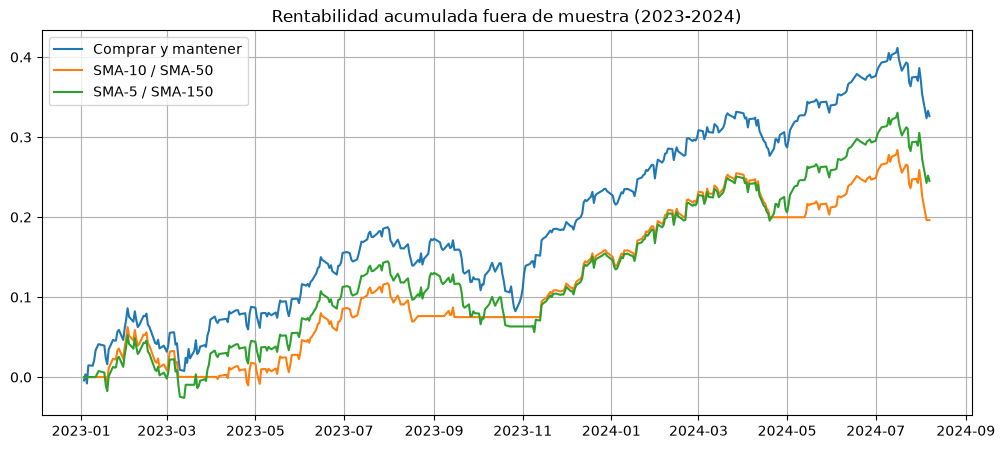

Fuera de muestra, SMA-5 / SMA-150 queda en el puesto 6 de 16


In [23]:
# 1. Mejor combinación dentro de muestra (2020-2022)
mejor = resultados.loc[resultados["Sharpe"].idxmax()]
w_short, w_long = int(mejor["short"]), int(mejor["long"])
print(f"Mejor combinación 2020-2022: SMA-{w_short} / SMA-{w_long} (Sharpe {mejor['Sharpe']:.2f})")

# 2. Evaluación fuera de muestra (2023 - agosto 2024)
rent_mejor = backtest_crossover(precios, w_short, w_long, "2023", "2024")
rent_10_50 = backtest_crossover(precios, 10, 50, "2023", "2024")
rent_bh = np.log(precios).diff().loc["2023":"2024"]

tabla_oos = pd.DataFrame({
    "Comprar y mantener": calcular_metricas(rent_bh),
    "SMA-10 / SMA-50": calcular_metricas(rent_10_50),
    f"SMA-{w_short} / SMA-{w_long}": calcular_metricas(rent_mejor),
})
display(tabla_oos.round(3))

plt.figure(figsize=(12, 5))
plt.plot(rent_bh.cumsum(), label="Comprar y mantener")
plt.plot(rent_10_50.cumsum(), label="SMA-10 / SMA-50")
plt.plot(rent_mejor.cumsum(), label=f"SMA-{w_short} / SMA-{w_long}")
plt.title("Rentabilidad acumulada fuera de muestra (2023-2024)")
plt.grid(True)
plt.legend()
plt.show()

# 3. Extra: ranking de todas las combinaciones fuera de muestra
resultados_oos = []
for ws in ventanas_short:
    for wl in ventanas_long:
        metricas = calcular_metricas(backtest_crossover(precios, ws, wl, "2023", "2024"))
        resultados_oos.append({"short": ws, "long": wl, "Sharpe": metricas["Sharpe"]})

resultados_oos = pd.DataFrame(resultados_oos).sort_values("Sharpe", ascending=False).reset_index(drop=True)
# Buscamos la fila de la combinación ganadora de 2020-2022 y vemos su posición en el ranking
fila = resultados_oos[(resultados_oos["short"] == w_short) & (resultados_oos["long"] == w_long)]
puesto = fila.index[0] + 1
print(f"Fuera de muestra, SMA-{w_short} / SMA-{w_long} queda en el puesto {puesto} de {len(resultados_oos)}")